This project uses a subset of the [sql-create-context](https://huggingface.co/datasets/b-mc2/sql-create-context) dataset, created by **b-mc2 (2023)** based on [WikiSQL](https://github.com/salesforce/WikiSQL) and [Spider](https://yale-lily.github.io/spider). The dataset is published under the [Creative Commons Attribution 4.0 International — CC BY 4.0](https://creativecommons.org/licenses/by/4.0/) license.

Data preprocessing included removing duplicate examples, selecting a subset, converting records into the `messages` format, and creating training, validation, and test splits.

In [1]:
!pip install -q "transformers>=4.55.0" "sqlglot==30.30.0" "trl>=1.17" "peft" "bitsandbytes" "datasets" "accelerate"
!pip uninstall -q -y torchao

In [2]:
import gc
import json
import os
import time
import re
from pathlib import Path

import pandas as pd
import torch
import sqlglot
from sqlglot import exp
from sqlglot.errors import SqlglotError
from datasets import load_dataset
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
from trl import SFTConfig, SFTTrainer
from google.colab import drive

assert torch.cuda.is_available(), "Для цього ноутбука потрібна GPU"
print(f"GPU: {torch.cuda.get_device_name()}")
print(f"Памʼять GPU: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")


drive.mount("/content/drive")

PROJECT_DIR = Path(
    "/content/drive/MyDrive/ai_systems/lab5/sql-lora"
)
ADAPTER_DIR = PROJECT_DIR / "qwen3-sql-lora-adapter"

ADAPTER_DIR.mkdir(parents=True, exist_ok=True)

print(f"Адаптер: {ADAPTER_DIR}")

GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition
Памʼять GPU: 102.0 GB
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Адаптер: /content/drive/MyDrive/ai_systems/lab5/sql-lora/qwen3-sql-lora-adapter


## Задача і чому потрібне донавчання

Задача: автоматиче перетворення запитань природною мовою на SQL-запити з урахуванням переданої схеми бази даних. Такий інструмент можуть використовувати працівники компаній, що не мають достатніх знань SQL, але їм потрібно отримувати інформацію з бази даних. Користувач описує потрібну інформацію, отримує сформований запит і може використати його для побудови звіту або вибірки даних.

На вхід моделі подаються запитання англійською мовою та схема бази даних у вигляді команд CREATE TABLE, які визначають назви таблиць, стовпців і типи даних. На виході має бути лише SQL-запит.

Донавчання обрано для адаптації невеликої моделі до конкретного формату входу та виходу й покращення її здатності зіставляти формулювання користувача з SQL-конструкціями. Звичайний промпт може пояснити задачу, однак не гарантує правильного вибору умов, агрегатних функцій або способу поєднання таблиць.

RAG не є основним методом для цієї задачі, оскільки необхідна схема вже передається моделі разом із запитанням. Основна складність полягає у правильному перетворенні наданої інформації на SQL, а не в пошуку відсутніх відомостей у зовнішніх документах.

## Модель і дані

Датасет: https://huggingface.co/datasets/b-mc2/sql-create-context

Ліцензія: cc-by-4.0

Це означає що можна:
- Копіювати та поширювати матеріал у будь-якому форматі чи на будь-якому носії.
- Адаптувати — мікшувати, змінювати та створювати на основі матеріалу нові твори (у тому числі для комерційних цілей).
Але виманається:
- Зазначення авторства (Attribution): Ви повинні вказати ім'я автора, надати посилання на ліцензію та позначити, чи вносили ви зміни до оригіналу.
- Не створювати додаткових обмежень: Ви не можете застосовувати юридичні чи технологічні засоби (наприклад, DRM), які б обмежували інших користувачів у правах, дозволених ліцензією.

In [3]:
raw_dataset = load_dataset("b-mc2/sql-create-context", split="train")
print(raw_dataset)

for raw in raw_dataset.shuffle(seed=0).select(range(3)):
    print("="*10)
    print("CONTEXT:")
    print(raw["context"])
    print("QUESTION:")
    print(raw["question"])
    print("ANSWER:")
    print(raw["answer"])


Dataset({
    features: ['answer', 'question', 'context'],
    num_rows: 78577
})
CONTEXT:
CREATE TABLE table_24463470_1 (unlock_order INTEGER, circuit VARCHAR)
QUESTION:
What is the lowest unlock order for the athens circuit?
ANSWER:
SELECT MIN(unlock_order) FROM table_24463470_1 WHERE circuit = "Athens"
CONTEXT:
CREATE TABLE table_name_99 (pick__number INTEGER, overall VARCHAR, position VARCHAR)
QUESTION:
What is the highest pick number of a defensive back with less than 136 overall points?
ANSWER:
SELECT MAX(pick__number) FROM table_name_99 WHERE overall < 136 AND position = "defensive back"
CONTEXT:
CREATE TABLE table_name_74 (engine VARCHAR, year INTEGER)
QUESTION:
Which engine has a year larger than 1956?
ANSWER:
SELECT engine FROM table_name_74 WHERE year > 1956


In [4]:
shuffled = raw_dataset.shuffle(seed=42)

seen, keep = set(), []

for i, context in enumerate(shuffled["context"]):
    key = context.strip()

    if key not in seen:
        seen.add(key)
        keep.append(i)

unique_context_dataset = shuffled.select(keep)

print(
    f"До відбору: {len(shuffled)}, "
    f"після: {len(unique_context_dataset)}"
)

До відбору: 78577, після: 72947


In [5]:
from pprint import pprint
SHORT_PROMPT = (
    "Translate the question into a SQL query using the provided database schema. "
    "Return only the SQL query, without explanations or Markdown."
)

def to_messages(raw):
    return {
        "messages": [
            {"role": "system", "content": SHORT_PROMPT},
            {"role": "user", "content": (
                f"Database Schema: {raw["context"]}\n\n"
                f"Question: {raw["question"]}"
            )},
            {"role": "assistant", "content": raw["answer"]},
        ],
        "chat_template_kwargs": {"enable_thinking": False},
    }

pprint(to_messages(unique_context_dataset[0]))

{'chat_template_kwargs': {'enable_thinking': False},
 'messages': [{'content': 'Translate the question into a SQL query using the '
                          'provided database schema. Return only the SQL '
                          'query, without explanations or Markdown.',
               'role': 'system'},
              {'content': 'Database Schema: CREATE TABLE table_name_50 (venue '
                          'VARCHAR, away_team VARCHAR)\n'
                          '\n'
                          'Question: When Essendon played away; where did they '
                          'play?',
               'role': 'user'},
              {'content': 'SELECT venue FROM table_name_50 WHERE away_team = '
                          '"essendon"',
               'role': 'assistant'}]}


In [6]:
N_TRAIN = 5000
N_VAL = 500
N_TEST = 1000

shuffled = unique_context_dataset.shuffle(seed=42)

dataset = shuffled.select(
    range(N_TRAIN + N_VAL + N_TEST)
).map(
    to_messages,
    remove_columns=shuffled.column_names,
)

train_dataset = dataset.select(range(N_TRAIN))

val_dataset = dataset.select(
    range(N_TRAIN, N_TRAIN + N_VAL)
)

test_dataset = dataset.select(
    range(N_TRAIN + N_VAL, N_TRAIN + N_VAL + N_TEST)
)

print(
    f"Тренувальний: {len(train_dataset)}, "
    f"валідаційний: {len(val_dataset)}, "
    f"тестовий: {len(test_dataset)}"
)

train_dataset[0]["messages"]

Тренувальний: 5000, валідаційний: 500, тестовий: 1000


[{'content': 'Translate the question into a SQL query using the provided database schema. Return only the SQL query, without explanations or Markdown.',
  'role': 'system'},
 {'content': 'Database Schema: CREATE TABLE Songs (Id VARCHAR)\n\nQuestion: How many songs are there?',
  'role': 'user'},
 {'content': 'SELECT COUNT(*) FROM Songs', 'role': 'assistant'}]

Модель: [Qwen/Qwen3-1.7B](https://huggingface.co/Qwen/Qwen3-1.7B)

Модель мала та злегкістю влізе в T4 GPU.

Обрано саме Qwen3-1.7B, а не Qwen3-1.7B-Base, щоб оцінити генерацію SQL із промптом ще до донавчання.

In [7]:
MODEL_NAME = "Qwen/Qwen3-1.7B"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    dtype=torch.float16,
    device_map="auto",
)

print(model)

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Qwen3ForCausalLM(
  (model): Qwen3Model(
    (embed_tokens): Embedding(151936, 2048)
    (layers): ModuleList(
      (0-27): 28 x Qwen3DecoderLayer(
        (self_attn): Qwen3Attention(
          (q_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (k_proj): Linear(in_features=2048, out_features=1024, bias=False)
          (v_proj): Linear(in_features=2048, out_features=1024, bias=False)
          (o_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (q_norm): Qwen3RMSNorm((128,), eps=1e-06)
          (k_norm): Qwen3RMSNorm((128,), eps=1e-06)
        )
        (mlp): Qwen3MLP(
          (gate_proj): Linear(in_features=2048, out_features=6144, bias=False)
          (up_proj): Linear(in_features=2048, out_features=6144, bias=False)
          (down_proj): Linear(in_features=6144, out_features=2048, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): Qwen3RMSNorm((2048,), eps=1e-06)
        (post_attention_layer

## Метрика й результат до донавчання

#### Normalized Exact Match

$$
EM = \frac{\text{Кількість збігів після нормалізації}}{\text{Загальна кількість тестових прикладів}} \times 100\%
$$

#### SQL Parse Rate
$$
\mathit{ParseRate} = \frac{\text{Кількість успішно розібраних запитів}}{\text{Загальна кількість відповідей}} \times 100\%
$$

In [8]:
from tqdm.auto import tqdm

def normalize_sql(text):
    """Повертає нормалізований SQL або None для неприйнятної відповіді."""
    text = text.strip()

    fence = re.fullmatch(
        r"```(?:sql)?\s*\n?(.*?)\n?```",
        text,
        flags=re.IGNORECASE | re.DOTALL,
    )
    if fence:
        text = fence.group(1).strip()

    try:
        statements = [
            statement
            for statement in sqlglot.parse(
                text,
                read="mysql",
                error_level=sqlglot.ErrorLevel.RAISE,
            )
            if statement is not None
        ]

        if len(statements) != 1:
            return None

        tree = statements[0]
        if not isinstance(tree, exp.Query):
            return None

        if tree.find(exp.DML) or tree.find(exp.DDL) or tree.find(exp.Into):
            return None

        return tree.sql(
            dialect="mysql",
            pretty=False,
            comments=False,
        )

    except (SqlglotError, ValueError):
        return None


def compute_sql_metrics(predictions, references):
    """Оцінює відповіді лише для еталонів, які проходять нормалізацію."""
    if len(predictions) != len(references):
        raise ValueError("Кількість прогнозів та еталонів має збігатися.")
    if len(references) == 0:
        raise ValueError("Набір для оцінювання порожній.")

    rows = []
    evaluated = matched = parsed = 0

    for prediction, reference in zip(predictions, references):
        normalized_reference = normalize_sql(reference)
        normalized_prediction = normalize_sql(prediction)

        reference_ok = normalized_reference is not None
        parse_ok = normalized_prediction is not None
        exact_match = (
            reference_ok
            and parse_ok
            and normalized_prediction == normalized_reference
        )

        if reference_ok:
            evaluated += 1
            parsed += int(parse_ok)
            matched += int(exact_match)

        rows.append({
            "reference": reference,
            "prediction": prediction,
            "normalized_reference": normalized_reference,
            "normalized_prediction": normalized_prediction,
            "reference_ok": reference_ok,
            "parse_ok": parse_ok,
            "exact_match": exact_match,
        })

    if evaluated == 0:
        raise ValueError("Жоден еталон не пройшов нормалізацію.")

    metrics = {
        "Normalized EM, %": 100 * matched / evaluated,
        "SQL Parse Rate, %": 100 * parsed / evaluated,
        "Оцінено прикладів": evaluated,
        "Виключено еталонів": len(references) - evaluated,
    }

    return metrics, pd.DataFrame(rows)


@torch.inference_mode()
def generate_sql_batch(
    model,
    tokenizer,
    user_messages,
    system_prompt,
    max_new_tokens=256,
):
    """Генерує відповідь для кожного повідомлення у списку."""
    if tokenizer.pad_token_id is None:
        tokenizer.pad_token = tokenizer.eos_token

    previous_padding_side = tokenizer.padding_side
    was_training = model.training

    try:
        model.eval()
        tokenizer.padding_side = "left"

        prompts = [
            tokenizer.apply_chat_template(
                [
                    {"role": "system", "content": system_prompt},
                    {"role": "user", "content": message},
                ],
                tokenize=False,
                add_generation_prompt=True,
                enable_thinking=False,
            )
            for message in user_messages
        ]

        inputs = tokenizer(
            prompts,
            return_tensors="pt",
            padding=True,
            add_special_tokens=False,
        ).to(model.device)

        outputs = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            num_beams=1,
            use_cache=True,
            pad_token_id=tokenizer.pad_token_id,
        )

        # Відкидаємо промпт разом із padding.
        new_tokens = outputs[:, inputs["input_ids"].shape[1]:]

        return [
            answer.strip()
            for answer in tokenizer.batch_decode(
                new_tokens,
                skip_special_tokens=True,
            )
        ]

    finally:
        tokenizer.padding_side = previous_padding_side
        model.train(was_training)


def evaluate_sql(
    model,
    tokenizer,
    dataset,
    system_prompt,
    batch_size=8,
    max_new_tokens=256,
):
    """Генерує SQL на всьому наборі та повертає метрики й таблицю."""
    if len(dataset) == 0 or batch_size < 1:
        raise ValueError("Потрібні непорожній dataset і batch_size >= 1.")

    user_messages = [
        example["messages"][1]["content"]
        for example in dataset
    ]
    references = [
        example["messages"][2]["content"]
        for example in dataset
    ]

    predictions = []

    for start in tqdm(
        range(0, len(dataset), batch_size),
        desc="Оцінювання SQL",
    ):
        predictions.extend(
            generate_sql_batch(
                model,
                tokenizer,
                user_messages[start:start + batch_size],
                system_prompt,
                max_new_tokens=max_new_tokens,
            )
        )

    metrics, results = compute_sql_metrics(predictions, references)
    results.insert(0, "input", user_messages)

    return metrics, results

In [9]:
def has_parseable_reference(example):
    return normalize_sql(example["messages"][2]["content"]) is not None


for name, dataset in [
    ("train", train_dataset),
    ("validation", val_dataset),
]:
    cleaned = dataset.filter(has_parseable_reference)
    print(f"{name}: {len(dataset)} → {len(cleaned)}")

    if name == "train":
        train_dataset = cleaned
    else:
        val_dataset = cleaned

train: 5000 → 4991
validation: 500 → 497


In [10]:
metrics_before, results_before = evaluate_sql(
    model,
    tokenizer,
    test_dataset,
    system_prompt=SHORT_PROMPT,
)

print(metrics_before)
display(results_before.head(10))

Оцінювання SQL:   0%|          | 0/125 [00:00<?, ?it/s]

{'Normalized EM, %': 25.225225225225227, 'SQL Parse Rate, %': 99.7997997997998, 'Оцінено прикладів': 999, 'Виключено еталонів': 1}


,input,reference,prediction,normalized_reference,normalized_prediction,reference_ok,parse_ok,exact_match
0,Database Schema: CREATE TABLE table_12547903_3...,SELECT branding FROM table_12547903_3 WHERE lo...,SELECT branding FROM table_12547903_3 WHERE lo...,SELECT branding FROM table_12547903_3 WHERE lo...,SELECT branding FROM table_12547903_3 WHERE lo...,True,True,True
1,Database Schema: CREATE TABLE table_name_54 (a...,SELECT affiliation FROM table_name_54 WHERE en...,SELECT affiliation FROM table_name_54 WHERE en...,SELECT affiliation FROM table_name_54 WHERE en...,SELECT affiliation FROM table_name_54 WHERE en...,True,True,True
2,Database Schema: CREATE TABLE table_25046766_3...,SELECT title FROM table_25046766_3 WHERE origi...,SELECT title FROM table_25046766_3 WHERE origi...,SELECT title FROM table_25046766_3 WHERE origi...,SELECT title FROM table_25046766_3 WHERE origi...,True,True,True
3,Database Schema: CREATE TABLE table_name_95 (f...,SELECT MAX(fall_08) FROM table_name_95 WHERE f...,SELECT MAX(fall_08) FROM table_name_95 WHERE f...,SELECT MAX(fall_08) FROM table_name_95 WHERE f...,SELECT MAX(fall_08) FROM table_name_95 WHERE f...,True,True,False
4,Database Schema: CREATE TABLE table_name_93 (c...,SELECT college FROM table_name_93 WHERE player...,SELECT college FROM table_name_93 WHERE player...,SELECT college FROM table_name_93 WHERE player...,SELECT college FROM table_name_93 WHERE player...,True,True,False
5,Database Schema: CREATE TABLE table_name_75 (l...,SELECT last_update FROM table_name_75 WHERE na...,SELECT last_update FROM table_name_75 WHERE na...,SELECT last_update FROM table_name_75 WHERE na...,SELECT last_update FROM table_name_75 WHERE na...,True,True,True
6,Database Schema: CREATE TABLE table_24706337_1...,SELECT ottoman_sultan FROM table_24706337_1 WH...,SELECT ottoman_sultan FROM table_24706337_1 WH...,SELECT ottoman_sultan FROM table_24706337_1 WH...,SELECT ottoman_sultan FROM table_24706337_1 WH...,True,True,True
7,Database Schema: CREATE TABLE table_22542179_3...,SELECT MIN(total_apps) FROM table_22542179_3 W...,SELECT MIN(total_apps) FROM table_22542179_3 W...,SELECT MIN(total_apps) FROM table_22542179_3 W...,SELECT MIN(total_apps) FROM table_22542179_3 W...,True,True,False
8,Database Schema: CREATE TABLE table_name_86 (s...,SELECT series FROM table_name_86 WHERE score =...,SELECT series FROM table_name_86 WHERE score =...,SELECT series FROM table_name_86 WHERE score =...,SELECT series FROM table_name_86 WHERE score =...,True,True,True
9,Database Schema: CREATE TABLE table_name_68 (n...,SELECT number FROM table_name_68 WHERE name_of...,SELECT number FROM table_name_68 WHERE name_of...,SELECT number FROM table_name_68 WHERE name_of...,SELECT number FROM table_name_68 WHERE name_of...,True,True,True


In [11]:
pprint(results_before.iloc[9].to_dict())

{'exact_match': True,
 'input': 'Database Schema: CREATE TABLE table_name_68 (number VARCHAR, '
          'name_of_the_song VARCHAR)\n'
          '\n'
          'Question: What is the number of the song named 實情?',
 'normalized_prediction': 'SELECT number FROM table_name_68 WHERE '
                          "name_of_the_song = '實情'",
 'normalized_reference': 'SELECT number FROM table_name_68 WHERE '
                         "name_of_the_song = '實情'",
 'parse_ok': True,
 'prediction': 'SELECT number FROM table_name_68 WHERE name_of_the_song = '
               "'實情';",
 'reference': 'SELECT number FROM table_name_68 WHERE name_of_the_song = "實情"',
 'reference_ok': True}


## Метод донавчання й гіперпараметри

In [12]:
import math
from transformers import set_seed

assert torch.cuda.is_available(), "Для навчання потрібна GPU."

set_seed(42)

tokenizer.padding_side = "right"

if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token


def valid_reference(example):
    return normalize_sql(example["messages"][2]["content"]) is not None


def add_token_length(example):
    encoded = tokenizer.apply_chat_template(
        example["messages"],
        tokenize=True,
        return_dict=True,
        padding=False,
        truncation=False,
        add_generation_prompt=False,
        enable_thinking=False,
    )

    return {
        "n_tokens": len(encoded["input_ids"]),
        "chat_template_kwargs": {"enable_thinking": False},
    }

train_for_sft = train_dataset.filter(valid_reference)
val_for_sft = val_dataset.filter(valid_reference)

train_for_sft = train_for_sft.map(add_token_length)
val_for_sft = val_for_sft.map(add_token_length)

lengths = pd.Series(
    list(train_for_sft["n_tokens"]) + list(val_for_sft["n_tokens"])
)

display(
    lengths.describe(percentiles=[0.5, 0.9, 0.95, 0.99]).to_frame(
        name="Довжина діалогу, токенів"
    )
)

MAX_LENGTH = max(512, math.ceil(int(lengths.max()) / 64) * 64)

train_for_sft = train_for_sft.remove_columns("n_tokens")
val_for_sft = val_for_sft.remove_columns("n_tokens")

print(f"Train: {len(train_dataset)} → {len(train_for_sft)}")
print(f"Validation: {len(val_dataset)} → {len(val_for_sft)}")
print(f"MAX_LENGTH: {MAX_LENGTH}")

,"Довжина діалогу, токенів"
count,5488.000000
mean,108.466290
std,17.775947
min,66.000000
50%,106.000000
90%,131.000000
95%,141.000000
99%,162.130000
max,260.000000


Train: 4991 → 4991
Validation: 497 → 497
MAX_LENGTH: 512


- Learning rate = 1e-4. Обрано як стартове значення для навчання LoRA-адаптерів: воно забезпечує достатньо помітні оновлення невеликої кількості навчальних параметрів. Разом із косинусним зменшенням learning rate це має дати стабільне зниження loss.
- Кількість епох = 2, або 624 кроки оптимізатора. Двох проходів по тренувальних даних має вистачити для суттєвого покращення результату.
- Розмір батча = 2 із накопиченням градієнтів за 8 мікробатчами. Малий фізичний батч зменшує використання GPU-пам’яті. Накопичення дає ефективний батч 2 × 8 = 16 прикладів на одне оновлення параметрів.
- LoRA rank, r=16. Це компроміс між гнучкістю адаптера та витратами пам’яті й обчислень. Такий ранг дозволяє адаптувати поведінку моделі, зберігаючи кількість навчальних параметрів відносно невеликою.
- lora_alpha=32. За стандартною формулою LoRA внесок адаптера масштабується на alpha/r = 32/16 = 2. Це обраний стартовий масштаб впливу адаптера на виходи шарів.

In [13]:
from peft import LoraConfig
from transformers import EarlyStoppingCallback
from transformers import TrainerCallback

RUN_DIR = "qwen3-sql-lora-run"
ADAPTER_DIR = "qwen3-sql-lora-adapter"

TRAIN_BATCH_SIZE = 2
GRADIENT_ACCUMULATION_STEPS = 8
NUM_EPOCHS = 2

lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    target_modules="all-linear",
    bias="none",
    task_type="CAUSAL_LM",
)

training_args = SFTConfig(
    output_dir=RUN_DIR,
    num_train_epochs=NUM_EPOCHS,
    learning_rate=1e-4,
    lr_scheduler_type="cosine",
    weight_decay=0.01,
    max_grad_norm=1.0,

    per_device_train_batch_size=TRAIN_BATCH_SIZE,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
    per_device_eval_batch_size=2,

    max_length=MAX_LENGTH,
    packing=False,
    assistant_only_loss=True,

    fp16=True,
    bf16=False,
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},

    eval_strategy="steps",
    eval_steps=50,
    save_strategy="steps",
    save_steps=50,
    save_total_limit=2,

    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,

    logging_strategy="steps",
    logging_steps=50,
    logging_first_step=False,

    prediction_loss_only=True,
    optim="adamw_torch",
    report_to="none",
    skip_memory_metrics=True,
    seed=42,
    data_seed=42,
)

model.config.use_cache = False

class FinalStepCallback(TrainerCallback):
    def on_step_end(self, args, state, control, **kwargs):
        if state.global_step >= state.max_steps:
            control.should_log = True
            control.should_evaluate = True
            control.should_save = True

        return control

trainer = SFTTrainer(
    model=model,
    args=training_args,
    train_dataset=train_for_sft,
    eval_dataset=val_for_sft,
    processing_class=tokenizer,
    peft_config=lora_config,
    callbacks=[
        EarlyStoppingCallback(
            early_stopping_patience=3,
            early_stopping_threshold=0.001,
        ),
        FinalStepCallback(),
    ],
)

for parameter in trainer.model.parameters():
    if parameter.requires_grad:
        parameter.data = parameter.data.float()

trainer.model.print_trainable_parameters()

effective_batch_size = (
    TRAIN_BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS
)

estimated_steps = (
    math.ceil(len(train_for_sft) / effective_batch_size)
    * NUM_EPOCHS
)

print(f"Ефективний batch size: {effective_batch_size}")
print(f"Орієнтовна максимальна кількість кроків: {estimated_steps}")

trainable params: 17,432,576 || all params: 1,738,007,552 || trainable%: 1.0030
Ефективний batch size: 16
Орієнтовна максимальна кількість кроків: 624


In [14]:
probe = trainer.data_collator([trainer.train_dataset[0]])

active_labels = probe["labels"][0] != -100
supervised_tokens = int(active_labels.sum())
input_tokens = int(probe["attention_mask"][0].sum())

assert 0 < supervised_tokens < input_tokens

print(f"Токенів у прикладі: {input_tokens}")
print(f"Токенів для обчислення loss: {supervised_tokens}")

print(
    tokenizer.decode(
        probe["input_ids"][0][active_labels],
        skip_special_tokens=False,
    )
)

del probe

Токенів у прикладі: 66
Токенів для обчислення loss: 11
<think>

</think>

SELECT COUNT(*) FROM Songs<|im_end|>



In [15]:
gc.collect()
torch.cuda.empty_cache()
torch.cuda.synchronize()
torch.cuda.reset_peak_memory_stats()

started_at = time.perf_counter()

train_result = trainer.train()

torch.cuda.synchronize()

elapsed_seconds = time.perf_counter() - started_at
peak_allocated_gb = torch.cuda.max_memory_allocated() / 1e9
peak_reserved_gb = torch.cuda.max_memory_reserved() / 1e9

training_stats = {
    "Тривалість, хв": elapsed_seconds / 60,
    "Кроків виконано": trainer.state.global_step,
    "Епох виконано": trainer.state.epoch,
    "Пікова allocated-пам’ять, GB": peak_allocated_gb,
    "Пікова reserved-пам’ять, GB": peak_reserved_gb,
    "Найкращий validation loss": trainer.state.best_metric,
    "Найкращий checkpoint": trainer.state.best_model_checkpoint,
    "Рання зупинка": (
        trainer.state.global_step < trainer.state.max_steps
    ),
}

display(
    pd.Series(training_stats).to_frame(name="Значення")
)

Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
50,0.277592,0.088365,0.091033,0.973760,87609.000000
100,0.077510,0.072158,0.060579,0.977707,174253.000000
150,0.067249,0.046958,0.056888,0.985411,261643.000000
200,0.050538,0.039503,0.045996,0.986756,347991.000000
250,0.045324,0.037265,0.045313,0.987063,434328.000000
300,0.038438,0.036516,0.036599,0.988110,520516.000000
350,0.033904,0.034912,0.032129,0.987955,606412.000000
400,0.021686,0.034811,0.025759,0.988052,693259.000000
450,0.024151,0.033526,0.026196,0.988427,780074.000000
500,0.023192,0.032277,0.027239,0.989136,866959.000000


,Значення
"Тривалість, хв",13.983233
Кроків виконано,624
Епох виконано,2.0
"Пікова allocated-пам’ять, GB",3.964639
"Пікова reserved-пам’ять, GB",4.752146
Найкращий validation loss,0.031772
Найкращий checkpoint,qwen3-sql-lora-run/checkpoint-624
Рання зупинка,False


,step,epoch,training_loss,validation_loss
0,50,0.160256,0.277592,0.088365
1,100,0.320513,0.077510,0.072158
2,150,0.480769,0.067249,0.046958
3,200,0.641026,0.050538,0.039503
4,250,0.801282,0.045324,0.037265
5,300,0.961538,0.038438,0.036516
6,350,1.121795,0.033904,0.034912
7,400,1.282051,0.021686,0.034811
8,450,1.442308,0.024151,0.033526
9,500,1.602564,0.023192,0.032277


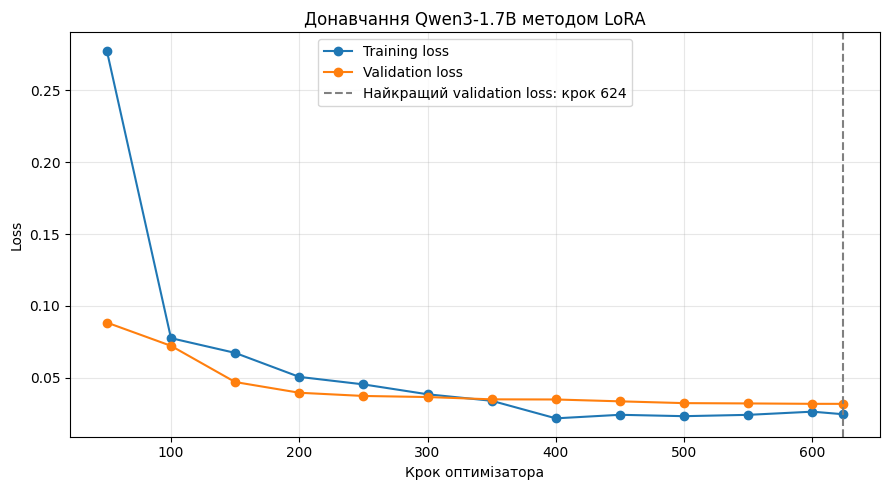

In [16]:
import matplotlib.pyplot as plt

def make_loss_table(log_history):
    records = [
        {
            "step": row["step"],
            "epoch": row.get("epoch"),
            "training_loss": row.get("loss"),
            "validation_loss": row.get("eval_loss"),
        }
        for row in log_history
        if (
            "step" in row
            and ("loss" in row or "eval_loss" in row)
        )
    ]

    return (
        pd.DataFrame(records)
        .groupby("step", as_index=False)
        .last()
        .sort_values("step")
        .reset_index(drop=True)
    )


loss_table = make_loss_table(
    trainer.state.log_history
)

display(loss_table.round(6))

train_curve = loss_table.dropna(
    subset=["training_loss"]
)

val_curve = loss_table.dropna(
    subset=["validation_loss"]
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    train_curve["step"],
    train_curve["training_loss"],
    marker="o",
    label="Training loss",
)

ax.plot(
    val_curve["step"],
    val_curve["validation_loss"],
    marker="o",
    label="Validation loss",
)

best_step = int(
    val_curve.loc[
        val_curve["validation_loss"].idxmin(),
        "step",
    ]
)

ax.axvline(
    best_step,
    color="gray",
    linestyle="--",
    label=f"Найкращий validation loss: крок {best_step}",
)

ax.set_xlabel("Крок оптимізатора")
ax.set_ylabel("Loss")
ax.set_title("Донавчання Qwen3-1.7B методом LoRA")
ax.grid(alpha=0.3)
ax.legend()

fig.tight_layout()
plt.show()

In [19]:
trainer.save_model(str(PROJECT_DIR))
tokenizer.save_pretrained(str(PROJECT_DIR))

trainer.save_state()

print(f"Адаптер збережено: {PROJECT_DIR}")

Адаптер збережено: /content/drive/MyDrive/ai_systems/lab5/sql-lora


## Результат після донавчання

In [20]:
import torch

from peft import AutoPeftModelForCausalLM
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(PROJECT_DIR)

model = AutoPeftModelForCausalLM.from_pretrained(
    PROJECT_DIR,
    dtype=torch.float16,
    device_map="auto",
    is_trainable=False,
)

model.config.use_cache = True
model.eval()

print("Модель з адаптером готова до використання.")

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Модель з адаптером готова до використання.


In [23]:
model.gradient_checkpointing_disable()
model.config.use_cache = True

loss_table.to_csv(
    f"{PROJECT_DIR}/loss_history.csv",
    index=False,
)

metrics_after, results_after = evaluate_sql(
    model,
    tokenizer,
    test_dataset,
    system_prompt=SHORT_PROMPT,
    batch_size=8,
    max_new_tokens=256,
)

display(
    pd.DataFrame({
        "До донавчання": metrics_before,
        "Після донавчання": metrics_after,
    }).round(2)
)

Оцінювання SQL:   0%|          | 0/125 [00:00<?, ?it/s]

,До донавчання,Після донавчання
"Normalized EM, %",25.23,77.98
"SQL Parse Rate, %",99.80,99.80
Оцінено прикладів,999.00,999.00
Виключено еталонів,1.00,1.00


## Аналіз помилок

In [32]:
model.eval()

CUSTOM_SCHEMA = """
CREATE TABLE orders (
    order_id INTEGER,
    customer_id INTEGER,
    status VARCHAR,
    total DECIMAL(10, 2)
);
""".strip()

sql_checks = [
    {
        "type": "Фільтрація за двома умовами",
        "question": (
            "List the order IDs for customer 42 "
            "where the total is at least 250."
        ),
        "reference": (
            "SELECT order_id FROM orders "
            "WHERE customer_id = 42 AND total >= 250"
        ),
    },
    {
        "type": "COUNT із фільтрацією",
        "question": (
            "How many orders have status 'pending' "
            "and a total below 300?"
        ),
        "reference": (
            "SELECT COUNT(*) FROM orders "
            "WHERE status = 'pending' AND total < 300"
        ),
    },
    {
        "type": "AVG із фільтрацією",
        "question": (
            "What is the average total of orders "
            "whose status is 'delivered'?"
        ),
        "reference": (
            "SELECT AVG(total) FROM orders "
            "WHERE status = 'delivered'"
        ),
    },
    {
        "type": "Сортування та LIMIT",
        "question": (
            "Return the order_id and total of the three orders "
            "with the highest total. "
            "Sort by total descending, then by order_id ascending "
            "to break ties."
        ),
        "reference": (
            "SELECT order_id, total FROM orders "
            "ORDER BY total DESC, order_id ASC LIMIT 3"
        ),
    },
]

custom_inputs = [
    f"Database Schema: {CUSTOM_SCHEMA}\n\n"
    f"Question: {check['question']}"
    for check in sql_checks
]

custom_predictions = generate_sql_batch(
    model=model,
    tokenizer=tokenizer,
    user_messages=custom_inputs,
    system_prompt=SHORT_PROMPT,
    max_new_tokens=256,
)

for number, (check, prediction) in enumerate(
    zip(sql_checks, custom_predictions),
    start=1,
):
    print(f"\nПриклад {number}: {check['type']}")
    print("Питання:", check["question"])
    print("Очікуваний SQL:", normalize_sql(check["reference"]))
    print("Відповідь моделі:", normalize_sql(prediction))
    print("Сходяться: ", normalize_sql(check["reference"]) == normalize_sql(prediction))


Приклад 1: Фільтрація за двома умовами
Питання: List the order IDs for customer 42 where the total is at least 250.
Очікуваний SQL: SELECT order_id FROM orders WHERE customer_id = 42 AND total >= 250
Відповідь моделі: SELECT order_id FROM orders WHERE status = 'complete' AND total >= 250 AND customer_id = 42
Сходяться:  False

Приклад 2: COUNT із фільтрацією
Питання: How many orders have status 'pending' and a total below 300?
Очікуваний SQL: SELECT COUNT(*) FROM orders WHERE status = 'pending' AND total < 300
Відповідь моделі: SELECT COUNT(order_id) FROM orders WHERE status = 'pending' AND total < 300
Сходяться:  False

Приклад 3: AVG із фільтрацією
Питання: What is the average total of orders whose status is 'delivered'?
Очікуваний SQL: SELECT AVG(total) FROM orders WHERE status = 'delivered'
Відповідь моделі: SELECT AVG(total) FROM orders WHERE status = 'delivered'
Сходяться:  True

Приклад 4: Сортування та LIMIT
Питання: Return the order_id and total of the three orders with the h

Перед порівнянням згенеровані та еталонні SQL-запити було нормалізовано функцією normalize_sql(). Тому виявлені незбіги не пов’язані лише з пробілами, регістром ключових слів або оформленням лапок. Водночас нормалізація не встановлює повну логічну еквівалентність запитів, тому кожну відповідь було додатково проаналізовано за змістом.

Приклад 1 (False). Фільтрація за двома умовами. Модель правильно використала колонку order_id і відтворила обидва задані обмеження: customer_id = 42 та total >= 250. Однак вона додала умову status = 'complete', якої немає в питанні. Унаслідок цього запит відбиратиме лише замовлення із зазначеним статусом, хоча потрібно повернути всі замовлення клієнта, які відповідають обмеженню суми. Цей приклад демонструє схильність моделі доповнювати запит обмеженнями, про які не просив користувач.

Приклад 2 (False). COUNT із фільтрацією. Модель правильно відтворила умови status = 'pending' і total < 300, але використала COUNT(order_id) замість COUNT(*). COUNT(\*) рахує всі відібрані рядки, а COUNT(order_id) лише рядки, у яких order_id не дорівнює NULL. У заданій схемі для order_id не оголошено обмеження NOT NULL або PRIMARY KEY, тому відсутність порожніх значень не гарантована. Якщо всі ідентифікатори заповнені, результати запитів збігатимуться. В іншому випадку модель може занизити кількість замовлень. Отже, це умовно еквівалентна відповідь, правильність якої залежить від властивостей даних.

Приклад 3 (True). AVG із фільтрацією. Відповідь моделі повністю збігається з еталоном після нормалізації. Модель правильно визначила необхідність обчислення середнього значення через AVG(total) та застосувала фільтр status = 'delivered'. Зайвих умов або операцій не додано.

Приклад 6 (True). Сортування та LIMIT. Згенерований запит повністю відповідає еталону. Модель правильно повернула обидві потрібні колонки, встановила сортування за total у спадному порядку та додаткове сортування за order_id у зростаючому порядку для однакових сум. Обмеження LIMIT 3 також відтворено правильно. Отже, на цьому прикладі модель виконала всі вимоги, включно з правилом розв’язання рівності значень.

In [37]:
GENERAL_PROMPT = (
    "You are a helpful assistant. "
    "Follow the user's instructions."
)

prompts = [
    "Calculate 17 multiplied by 24.",

    "Translate into Ukrainian: "
    "'The meeting will take place tomorrow morning.'",

    "Return exactly three color names, separated by commas, "
    "without any other text.",

    "Summarize this text in one English sentence: "
    "Marta visited the library on Monday. "
    "She borrowed two books. She returned both books on Friday.",

    "Explain the difference between a Python list "
    "and a Python tuple in two sentences.",

    "Write a Python function is_even(n) that returns True "
    "for even integers and False for odd integers. "
    "Return only the code.",
]

model.eval()

with model.disable_adapter():
    answers_before = generate_sql_batch(
        model=model,
        tokenizer=tokenizer,
        user_messages=prompts,
        system_prompt=GENERAL_PROMPT,
        max_new_tokens=256,
    )

answers_after = generate_sql_batch(
    model=model,
    tokenizer=tokenizer,
    user_messages=prompts,
    system_prompt=GENERAL_PROMPT,
    max_new_tokens=256,
)

for prompt, before, after in zip(
    prompts, answers_before, answers_after
):
    print("\nПРОМПТ:", prompt)
    print("\nДО НАВЧАННЯ:")
    print(before)
    print("\nПІСЛЯ НАВЧАННЯ:")
    print(after)


ПРОМПТ: Calculate 17 multiplied by 24.

ДО НАВЧАННЯ:
17 multiplied by 24 is 408.

ПІСЛЯ НАВЧАННЯ:
17 × 24 = 408

ПРОМПТ: Translate into Ukrainian: 'The meeting will take place tomorrow morning.'

ДО НАВЧАННЯ:
Сімейна розмовка відбудеться завтра раніше.

ПІСЛЯ НАВЧАННЯ:
Тема зустрічі відбудеться завтра ранок.

ПРОМПТ: Return exactly three color names, separated by commas, without any other text.

ДО НАВЧАННЯ:
red,blue,green

ПІСЛЯ НАВЧАННЯ:
red,blue,green

ПРОМПТ: Summarize this text in one English sentence: Marta visited the library on Monday. She borrowed two books. She returned both books on Friday.

ДО НАВЧАННЯ:
Marta visited the library on Monday, borrowed two books, and returned them on Friday.

ПІСЛЯ НАВЧАННЯ:
Marta visited the library on Monday, borrowed two books, and returned both on Friday.

ПРОМПТ: Explain the difference between a Python list and a Python tuple in two sentences.

ДО НАВЧАННЯ:
A Python list is a dynamic, mutable sequence of elements that can be modified afte

## Висновок

У результаті виконання лабораторної роботи я дослідив донавчання мовної моделі Qwen3-1.7B методом LoRA для перетворення запитань природною мовою на SQL-запити за заданою схемою бази даних. Для донавченої моделі показник Normalized EM зріс із 25.23% до 77.98%, тоді як SQL Parse Rate залишився на рівні 99.80%. Навчання протягом двох епох тривало близько 14 хвилин, що підтвердило можливість застосування LoRA за обмежених обчислювальних ресурсів.

Аналіз власних прикладів показав, що модель може генерувати синтаксично коректні запити, але додавати необґрунтовані умови, пропускати потрібні обмеження та неправильно обробляти NULL. Це засвідчило необхідність доповнювати автоматичні метрики ручною перевіркою змісту відповідей. На перевірених загальних запитах погіршення відповідей після донавчання не виявлено.

## Завантаження адаптера на Hugging Face Hub

In [40]:
%pip install -q huggingface_hub

In [39]:
from google.colab import userdata
HUGHUB_KEY = userdata.get('HUB_KEY')

In [45]:
from getpass import getpass
from huggingface_hub import login, HfApi

login(
    token=HUGHUB_KEY,
    add_to_git_credential=False,
)

api = HfApi()

username = api.whoami()["name"]
REPO_ID = f"{username}/qwen3-1.7b-text-to-sql-lora"

print(f"Репозиторій: {REPO_ID}")

print("Файли адаптера:")
for path in sorted(PROJECT_DIR.iterdir()):
    if path.is_file():
        print(path.name)

Репозиторій: Delinev/qwen3-1.7b-text-to-sql-lora
Файли адаптера:
README.md
adapter_config.json
adapter_model.safetensors
chat_template.jinja
loss_history.csv
tokenizer.json
tokenizer_config.json
training_args.bin


In [46]:
api.create_repo(
    repo_id=REPO_ID,
    repo_type="model",
    private=False,
    exist_ok=True,
)

api.upload_folder(
    repo_id=REPO_ID,
    repo_type="model",
    folder_path=str(PROJECT_DIR),
    commit_message="Upload Text-to-SQL LoRA adapter and model card",
)

print(f"https://huggingface.co/{REPO_ID}")

https://huggingface.co/Delinev/qwen3-1.7b-text-to-sql-lora


In [47]:
for filename in api.list_repo_files(
    repo_id=REPO_ID,
    repo_type="model",
):
    print(filename)

.gitattributes
README.md
adapter_config.json
adapter_model.safetensors
chat_template.jinja
loss_history.csv
tokenizer.json
tokenizer_config.json
training_args.bin


In [50]:
import torch

from peft import AutoPeftModelForCausalLM
from transformers import AutoTokenizer

hub_tokenizer = AutoTokenizer.from_pretrained(REPO_ID)

hub_model = AutoPeftModelForCausalLM.from_pretrained(
    REPO_ID,
    torch_dtype=torch.float16,
    device_map="auto",
)

hub_model.eval()

hub_predictions = generate_sql_batch(
    model=hub_model,
    tokenizer=tokenizer,
    user_messages=custom_inputs,
    system_prompt=SHORT_PROMPT,
    max_new_tokens=256,
)

for number, (check, prediction) in enumerate(
    zip(sql_checks, hub_predictions),
    start=1,
):
    print(f"\nПриклад {number}: {check['type']}")
    print("Питання:", check["question"])
    print("Очікуваний SQL:", normalize_sql(check["reference"]))
    print("Відповідь моделі:", normalize_sql(prediction))
    print("Сходяться: ", normalize_sql(check["reference"]) == normalize_sql(prediction))

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]


Приклад 1: Фільтрація за двома умовами
Питання: List the order IDs for customer 42 where the total is at least 250.
Очікуваний SQL: SELECT order_id FROM orders WHERE customer_id = 42 AND total >= 250
Відповідь моделі: SELECT order_id FROM orders WHERE status = 'complete' AND total >= 250 AND customer_id = 42
Сходяться:  False

Приклад 2: COUNT із фільтрацією
Питання: How many orders have status 'pending' and a total below 300?
Очікуваний SQL: SELECT COUNT(*) FROM orders WHERE status = 'pending' AND total < 300
Відповідь моделі: SELECT COUNT(order_id) FROM orders WHERE status = 'pending' AND total < 300
Сходяться:  False

Приклад 3: AVG із фільтрацією
Питання: What is the average total of orders whose status is 'delivered'?
Очікуваний SQL: SELECT AVG(total) FROM orders WHERE status = 'delivered'
Відповідь моделі: SELECT AVG(total) FROM orders WHERE status = 'delivered'
Сходяться:  True

Приклад 4: Сортування та LIMIT
Питання: Return the order_id and total of the three orders with the h